# Provider networks: practitioners, the organizations they bill through, and hospitals

The warehouse holds three public CMS sources that each describe one side of how US health care is organized: NPPES (who is licensed, where, in what specialty), the Medicare Public Provider Enrollment Files (PPEF: who is enrolled in Medicare, and which organization each clinician *reassigns* their Medicare billing to) and the Provider of Services file (POS: every certified hospital). `healthcare-ledger graph-build` joins them into one graph, quarter by quarter from February 2016 to September 2026:

* **practitioner** nodes (individual enrollees, by PECOS associate id) and **organization** nodes (organization enrollees, by PECOS associate id, which PECOS issues once per legal entity, so once per tax id);
* **reassignment** edges from a practitioner to each organization that bills Medicare for them;
* **hospital** nodes (active POS hospitals, by CCN) and **hospital_link** edges from a hospital's enrollment to its CCN;
* **post_acute_facility** nodes (active POS nursing homes and home health agencies, by CCN) and **post_acute_link** edges from their enrollments;
* with `--compendium`, **system** nodes and **system_link** edges from AHRQ's Compendium of U.S. Health Systems, by Compendium year (2016, 2018, 2020-2023): organizations by associate id, hospitals, nursing homes and home health agencies by CCN.

This notebook does three things a health economist would ask of such a graph, each the measure of a published paper, extended over the ten years the PPEF covers, and then scores the graph against AHRQ's claims-based assignment of physicians to groups and systems:

1. **Group size.** Welch, Cuellar, Stearns and Bindman (*Health Affairs* 2013) and Muhlestein and Smith (*Health Affairs* 2016) measured the shift of physicians from small practices into large groups, defining a group by its Medicare tax id or Physician Compare group id.
2. **Market concentration.** Capps, Dranove and Ody (*Health Affairs* 2017) and Fulton (*Health Affairs* 2017) computed Herfindahl-Hirschman indexes (HHI) of physician organizations within local markets.
3. **Vertical integration.** Luo, Black and others (*HSR* 2024) count physicians billing under hospital-related tax ids; their "basic TIN" variant, a tax id that itself bills as a hospital, is the one the PPEF alone can reproduce; AHRQ's system membership (section 6) is the public stand-in for their full measure.

`README.md` in this directory summarizes the literature the design follows and what the results show.

## 0. Open the graph

The graph is a directory of Parquet files written by `healthcare-ledger graph-build --warehouse <dir> --out <dir>` (`$LEDGER_GRAPH`, or the repository's `graph/` by default). Every table is an interval table with the warehouse's version semantics: a row holds on date `d` when `effective_date <= d` and `end_date` is NULL or later than `d`, and the interval endpoints are PPEF quarter dates, listed in `quarters.csv`. The two Compendium tables are the exception: they are keyed by `year`, because AHRQ describes a calendar year, and section 6 reads each year on the PPEF quarter nearest 1 July. Without `--compendium` they are empty and section 6 shows nothing. `graph-build` also writes the group primitives that sections 3 and 4b build on (`physician_q`, `physician_edge`, `group_size` and, with `--medicaid`, `medicaid_volume` and `main_group`), from SQL files in `src/healthcare_ledger/derived/sql/` that any study of physician groups shares; the notebook shows each file where it is first used. Without `--medicaid` the two Medicaid tables are empty and section 4b shows nothing.

In [1]:
import json, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import healthcare_ledger
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

GRAPH = Path(os.environ.get("LEDGER_GRAPH", "../../graph")).resolve()
manifest = json.load(open(GRAPH / "manifest.json"))
print("graph built", manifest["generated_at"], "from", manifest["warehouse"], "|",
      manifest["quarters"], "quarters", manifest["first_as_of_date"], "to", manifest["last_as_of_date"])

con = healthcare_ledger.connect(graph=GRAPH)      # one view per graph table: practitioner, organization, ..., quarters
# Section 6: the annual AHRQ Compendium tables, present when the graph was built with --compendium
if "system_link" not in manifest["tables"]:
    con.execute("CREATE TABLE system (year INTEGER, health_sys_id VARCHAR, health_sys_name VARCHAR, total_mds INTEGER)")
    con.execute("CREATE TABLE system_link (year INTEGER, node_type VARCHAR, node_id VARCHAR, compendium_id VARCHAR, "
                "name VARCHAR, health_sys_id VARCHAR, md_ppas_physicians INTEGER, via VARCHAR)")
con.execute("CREATE TABLE hrr AS SELECT * FROM read_csv('../../reference/zip_hrr_2019.csv', all_varchar = true)")
con.execute("""
CREATE TABLE cbsa AS   -- each ZIP's ZCTA, the county holding most of its 2010 population, and that county's 2015 CBSA
SELECT z.zcta AS zip5, z.county_fips, c.cbsa, c.cbsa_title, c.cbsa_type
FROM read_csv('../../reference/zcta_county.csv', all_varchar = true) z
LEFT JOIN read_csv('../../reference/county_cbsa_2015.csv', all_varchar = true) c USING (county_fips)
""");

graph built 2026-10-27T19:21:04 from warehouse | 43 quarters 2016-02-01 to 2026-09-29


## 1. What the graph holds

Nodes and edges in force on each quarter's date. A reassignment row of the PPEF links one individual *enrollment* to one organization *enrollment*; the graph collapses enrollments to associate ids, so a practitioner enrolled in two states who reassigns to two enrollments of the same group has one edge. `n_reassignment_dropped` counts the PPEF rows that cannot become an edge because one side is missing from that quarter's enrollment file or the receiving side is an individual: about 4,000 a quarter, 0.1 to 0.2 percent.

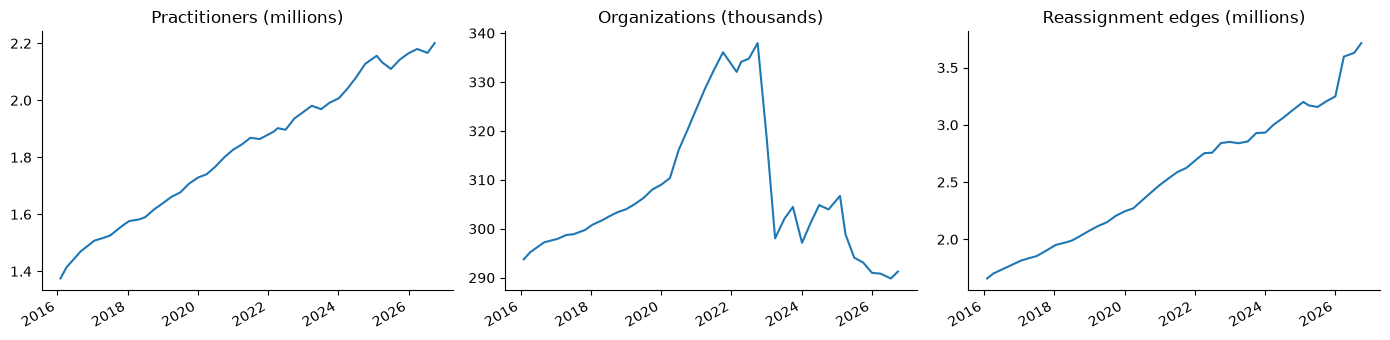

,n_practitioner,n_organization,n_hospital,n_reassignment,n_hospital_link,n_post_acute_facility,n_post_acute_link,n_reassignment_rows,n_reassignment_dropped,n_hospital_enrollments
as_of_date,,,,,,,,,,
2016-02-01,1374813,293748,7168,1657888,8233,28012,23190,1723387,4099,9633
2019-04-01,1661343,305041,7106,2116414,8237,27057,23062,2200010,3898,9524
2022-04-12,1902265,334126,7288,2753109,8673,26709,22648,2885596,4259,10034
2022-12-30,1958170,319281,7274,2851231,8594,26655,22442,2993414,4192,9945
2023-03-31,1980794,298045,7256,2839606,8476,26582,22315,2986068,4215,9814
2026-01-02,2165294,290991,7023,3248781,8026,27318,21991,3469977,3611,9188
2026-04-01,2180085,290823,7022,3596693,8028,27352,21870,3857023,4156,9180
2026-09-29,2200672,291259,7031,3714552,7970,27340,21835,3996400,4041,9135


In [2]:
q = con.sql("SELECT * FROM quarters ORDER BY as_of_date").df().set_index("as_of_date")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
(q[["n_practitioner"]] / 1e6).plot(ax=axes[0], legend=False, title="Practitioners (millions)")
(q[["n_organization"]] / 1e3).plot(ax=axes[1], legend=False, title="Organizations (thousands)")
(q[["n_reassignment"]] / 1e6).plot(ax=axes[2], legend=False, title="Reassignment edges (millions)")
for ax in axes: ax.set_xlabel("")
plt.tight_layout(); plt.show()
q.iloc[[0, 12, 24, 27, 28, 39, 40, -1], 1:]

Two breaks in these series come from the files, not from the market, and every measure below has to be read around them.

* **Late 2022 to early 2023: organizations fall by 40,000** (338,000 on 2022-09-30, 298,000 on 2023-03-31) while practitioners and edges keep growing. The organization enrollments that leave are mostly small ones; the share of physicians in one-physician organizations drops a point over the two quarters (section 3). It reads as a PECOS clean-up of inactive enrollments.
* **April 2026: 350,000 more edges in one quarter.** CMS began to publish the reassignments of physician assistants, who had almost none in the file before. The cell below shows it. Section 3 counts physicians only, so the measures below are not affected.

In [3]:
con.sql("""
WITH pa AS (
    SELECT q.as_of_date, p.pac_id
    FROM quarters q
    JOIN practitioner p ON p.effective_date <= q.as_of_date AND (p.end_date IS NULL OR p.end_date > q.as_of_date)
    WHERE list_contains(p.provider_type_codes, '14-97') AND q.as_of_date >= DATE '2025-07-01'),
edge AS (
    SELECT DISTINCT q.as_of_date, r.practitioner_pac_id
    FROM quarters q
    JOIN reassignment r ON r.effective_date <= q.as_of_date AND (r.end_date IS NULL OR r.end_date > q.as_of_date)
    WHERE q.as_of_date >= DATE '2025-07-01')
SELECT pa.as_of_date, count(*) AS physician_assistants_enrolled,
       count(edge.practitioner_pac_id) AS with_a_reassignment
FROM pa LEFT JOIN edge ON edge.as_of_date = pa.as_of_date AND edge.practitioner_pac_id = pa.pac_id
GROUP BY 1 ORDER BY 1
""").df()

,as_of_date,physician_assistants_enrolled,with_a_reassignment
0,2025-07-01,161822,650
1,2025-10-01,163912,1133
2,2026-01-02,167052,12333
3,2026-04-01,169512,167860
4,2026-07-17,171433,169633
5,2026-09-29,173356,171541


## 2. Linking organizations to hospitals

The POS file and the PPEF share no identifier. The PPEF practice-location file has only city, state and ZIP, and the release suppresses the NPPES "other identifier" slots where a hospital might have typed its CCN. So `graph-build` matches each hospital, critical access hospital or rural emergency hospital *enrollment* to an active POS hospital in the same state, through the NPPES practice address and phone of the enrollment's NPI: same phone and street number (rule 1), same street number within the ZIP (rule 2), or same phone (rule 3). An enrollment whose best rule ties between two CCNs is left unlinked, because ties are wrong a third to a half of the time.

CMS publishes the true link for recent months: the *Hospital Enrollments* file on data.cms.gov gives each hospital enrollment's CCN. `data/hospital_enrollments_2026-09-29.csv` is the file of the same date as the last PPEF quarter, cut to its identifiers. A third of its rows carry a CCN that is not a POS hospital: swing-bed, psychiatric-unit and rehabilitation-unit CCNs (`51Z312`, `44S058`) that share the hospital's address and enrollment, for which the file sometimes gives the parent CCN in `cah_or_hospital_ccn`. The check is therefore on the enrollments whose true CCN, or parent CCN, is a POS hospital.

In [4]:
con.execute("""
CREATE TABLE link_check AS
WITH pos AS (SELECT ccn FROM hospital WHERE end_date IS NULL),
truth AS (
    SELECT enrollment_id,
           CASE WHEN ccn IN (SELECT ccn FROM pos) THEN ccn
                WHEN cah_or_hospital_ccn IN (SELECT ccn FROM pos) THEN cah_or_hospital_ccn END AS true_ccn
    FROM read_csv('data/hospital_enrollments_2026-09-29.csv', all_varchar = true))
SELECT t.enrollment_id, t.true_ccn, l.ccn AS linked_ccn, l.match_rule
FROM truth t
LEFT JOIN hospital_link l ON l.enrollment_id = t.enrollment_id AND l.end_date IS NULL
WHERE t.true_ccn IS NOT NULL
""")
con.sql("""
SELECT coalesce(CAST(match_rule AS VARCHAR), 'not linked') AS match_rule, count(*) AS enrollments,
       count(*) FILTER (WHERE linked_ccn = true_ccn) AS correct,
       round(100 * count(*) FILTER (WHERE linked_ccn = true_ccn) / count(*), 1) AS precision_pct
FROM link_check GROUP BY ALL
UNION ALL
SELECT 'all', count(*), count(*) FILTER (WHERE linked_ccn = true_ccn),
       round(100 * count(*) FILTER (WHERE linked_ccn = true_ccn) / count(*), 1)
FROM link_check
ORDER BY 1
""").df()

,match_rule,enrollments,correct,precision_pct
0,1,3156,3155,100.0
1,2,1934,1916,99.1
2,3,173,168,97.1
3,all,5915,5239,88.6
4,not linked,652,0,0.0


Read `precision_pct` on the rule rows as precision and on the `all` row as recall: 89 percent of the linkable hospital enrollments get the right CCN, and a CCN the graph gives is right 97 to 100 percent of the time, depending on the rule. The check is for the last quarter only, the one with a true file; the rules are the same in every quarter, and the number of links tracks the number of hospital enrollments from 2016 on (`quarters.csv`: 8,233 of 9,633 in February 2016, 7,970 of 9,135 in September 2026).

Nothing below depends on the CCN link. It is in the graph so that hospitals' own attributes (beds, location, ownership type) can be attached to the organizations that bill for them: the step the literature calls rolling tax ids up to systems, which section 6 leaves for further work.

### Nursing homes and home health agencies

`graph-build` links skilled nursing facility (`00-18`) and home health agency (`00-06`) enrollments the same way, to the active POS facilities of the same type: QIES categories 02, 03, 04 and 10 (nursing homes) and 05 (home health), and the iQIES types that replaced them once CMS moved them (20 and 3; home health from the December 2023 file, nursing homes from September 2025). CMS's *Skilled Nursing Facility Enrollments* and *Home Health Agency Enrollments* files of 29 September 2026 give the true CCN of each enrollment (`data/snf_enrollments_2026-09-29.csv`, `data/hha_enrollments_2026-09-29.csv`), scored here on the enrollments whose CCN is an active facility of the type:

In [5]:
con.execute("""
CREATE TABLE facility_check AS
WITH truth AS (
    SELECT 'nursing_home' AS facility_type, enrollment_id, ccn FROM read_csv('data/snf_enrollments_2026-09-29.csv', all_varchar = true)
    UNION ALL
    SELECT 'home_health', enrollment_id, ccn FROM read_csv('data/hha_enrollments_2026-09-29.csv', all_varchar = true))
SELECT t.facility_type, t.enrollment_id, t.ccn AS true_ccn, l.ccn AS linked_ccn, l.match_rule
FROM truth t
LEFT JOIN post_acute_link l ON l.enrollment_id = t.enrollment_id AND l.end_date IS NULL
WHERE t.ccn IN (SELECT ccn FROM post_acute_facility f WHERE f.end_date IS NULL AND f.facility_type = t.facility_type)
""")
con.sql("""
SELECT facility_type, coalesce(CAST(match_rule AS VARCHAR), 'not linked') AS match_rule, count(*) AS enrollments,
       count(*) FILTER (WHERE linked_ccn = true_ccn) AS correct,
       round(100 * count(*) FILTER (WHERE linked_ccn = true_ccn) / count(*), 1) AS precision_pct
FROM facility_check GROUP BY ALL
UNION ALL
SELECT facility_type, 'all', count(*), count(*) FILTER (WHERE linked_ccn = true_ccn),
       round(100 * count(*) FILTER (WHERE linked_ccn = true_ccn) / count(*), 1)
FROM facility_check GROUP BY ALL
ORDER BY 1, 2
""").df()

,facility_type,match_rule,enrollments,correct,precision_pct
0,home_health,1,5213,5190,99.6
1,home_health,2,1659,1586,95.6
2,home_health,3,909,900,99.0
3,home_health,all,11308,7676,67.9
4,home_health,not linked,3527,0,0.0
5,nursing_home,1,11265,11263,100.0
6,nursing_home,2,2229,2228,100.0
7,nursing_home,3,283,277,97.9
8,nursing_home,all,14214,13768,96.9
9,nursing_home,not linked,437,0,0.0


Read `precision_pct` on the rule rows as precision and on the `all` row as recall. **Nursing homes link almost perfectly**: 13,768 of 14,214 linkable enrollments (96.9 percent) get the right CCN, and the links are right 99.9 percent of the time. **Home health agencies link precisely but less often**: the links are right 98.7 percent of the time, but only 7,676 of 11,308 enrollments (67.9 percent) are linked, because agencies often give NPPES a billing or branch office that is not the address POS certifies. As with hospitals, nothing below depends on these links: they connect facilities to the organizations that bill for them, for the ownership work of section 8.


## 3. Group size: replicating Welch et al. (2013) and Muhlestein and Smith (2016)

Welch et al. defined a physician group as a Medicare tax id, sized it by the physicians billing under it, and put a physician who billed under several tax ids in the one with the most of their charges. They found the share of physicians in groups of more than 50 rising from 30.9 to 35.6 percent between 2009 and 2011. Muhlestein and Smith used Physician Compare's group ids, which are PECOS associate ids, the same ids this graph uses, and found the share in groups of 100 or more rising from 29.6 to 35.1 percent between June 2013 and December 2015, and the share in groups of nine or fewer falling from 40.1 to 35.3 percent.

The graph has their group id but not their claims, so it cannot pick a physician's main group. It shows two substitutes. **Fractional**: a physician with `k` reassignments counts `1/k` in each group, the convention when nothing ranks the groups. **Single group**: only the physicians who reassign to exactly one organization, for whom the choice does not arise (half of them). A physician is a practitioner whose NPPES primary taxonomy is an allopathic or osteopathic physician code (`20*`).

**Group size counts each physician once.** A group's size is the sum of `1/k` over the physicians reassigning to it, the number of physicians it has when every physician is spread over their groups. That is how a claims-based count behaves: MD-PPAS, which AHRQ and the papers' successors use, puts each physician in one tax id, so the physicians of all groups add up to the physicians. A plain headcount counts a physician with four reassignments in four groups, and section 6 shows that it overstates the share in large groups by 10 points against MD-PPAS on the same tax ids, while the fractional size matches it within two.

The physicians, their edges and the group sizes are built by `graph-build` (`derived/primitives.py`) and read here from the graph directory, because every study of physician groups needs them with exactly this meaning:

`src/healthcare_ledger/derived/sql/physician_q.sql`, written to `physician_quarter.parquet`:

```sql
-- physician_q: a physician (a practitioner whose NPPES primary taxonomy is an allopathic or osteopathic
-- physician code, 20*) on each quarter's date, with their Medicare specialties and practice ZIP and state
SELECT q.as_of_date, p.pac_id, p.provider_type_codes, p.practice_zip5, p.practice_state
FROM quarters q
JOIN practitioner p ON p.effective_date <= q.as_of_date AND (p.end_date IS NULL OR p.end_date > q.as_of_date)
WHERE p.taxonomy_code LIKE '20%'
```

`src/healthcare_ledger/derived/sql/physician_edge.sql`, written to `physician_edge.parquet`:

```sql
-- physician_edge: a physician's reassignments in force on each quarter's date, with k, the number of
-- organizations the physician reassigns to that quarter
SELECT e.*, count(*) OVER (PARTITION BY e.as_of_date, e.practitioner_pac_id) AS k
FROM (SELECT q.as_of_date, r.practitioner_pac_id, r.organization_pac_id
      FROM quarters q
      JOIN reassignment r ON r.effective_date <= q.as_of_date AND (r.end_date IS NULL OR r.end_date > q.as_of_date)) e
SEMI JOIN physician_q p ON p.as_of_date = e.as_of_date AND p.pac_id = e.practitioner_pac_id
```

`src/healthcare_ledger/derived/sql/group_size.sql`, written to `group_size.parquet`:

```sql
-- group_size: each organization's physicians on each quarter's date, as a headcount and as the sum of 1/k,
-- which counts each physician once over all their groups
SELECT as_of_date, organization_pac_id, count(*) AS headcount, sum(1.0 / k) AS physicians
FROM physician_edge GROUP BY ALL
```

In [6]:
# section 3's physicians (physician_quarter, physician_q above), their reassignment edges and group sizes, written by
# graph-build (the SQL is above)
con.execute("CREATE VIEW physician_q AS SELECT * FROM physician_quarter")
con.execute("""
CREATE TABLE size_shares AS
SELECT e.as_of_date, w.weighting,
       100 * sum(w.wt) FILTER (WHERE g.physicians < 10) / sum(w.wt) AS "9 or fewer",
       100 * sum(w.wt) FILTER (WHERE g.physicians > 50) / sum(w.wt) AS "more than 50",
       100 * sum(w.wt) FILTER (WHERE g.physicians >= 100) / sum(w.wt) AS "100 or more",
       100 * sum(w.wt) FILTER (WHERE g.physicians >= 500) / sum(w.wt) AS "500 or more"
FROM physician_edge e
JOIN group_size g USING (as_of_date, organization_pac_id)
CROSS JOIN LATERAL (VALUES ('fractional', 1.0 / e.k), ('single group', CASE WHEN e.k = 1 THEN 1.0 ELSE 0.0 END)) w(weighting, wt)
GROUP BY ALL
""")
coverage = con.sql("""
SELECT p.as_of_date, count(*) AS physicians,
       count(*) FILTER (WHERE e.k IS NOT NULL) AS with_a_reassignment,
       count(*) FILTER (WHERE e.k = 1) AS with_one,
       avg(e.k) AS mean_reassignments
FROM physician_q p
LEFT JOIN (SELECT DISTINCT as_of_date, practitioner_pac_id, k FROM physician_edge) e
       ON e.as_of_date = p.as_of_date AND e.practitioner_pac_id = p.pac_id
GROUP BY 1 ORDER BY 1
""").df().set_index("as_of_date")
coverage.iloc[[0, 12, 24, 36, -1]].round(2)

,physicians,with_a_reassignment,with_one,mean_reassignments
as_of_date,,,,
2016-02-01,705387,638048,414377,1.62
2019-04-01,783455,707403,430444,1.78
2022-04-12,854975,781680,427223,2.01
2025-04-01,903114,825368,438817,2.09
2026-09-29,926673,854721,454639,2.13


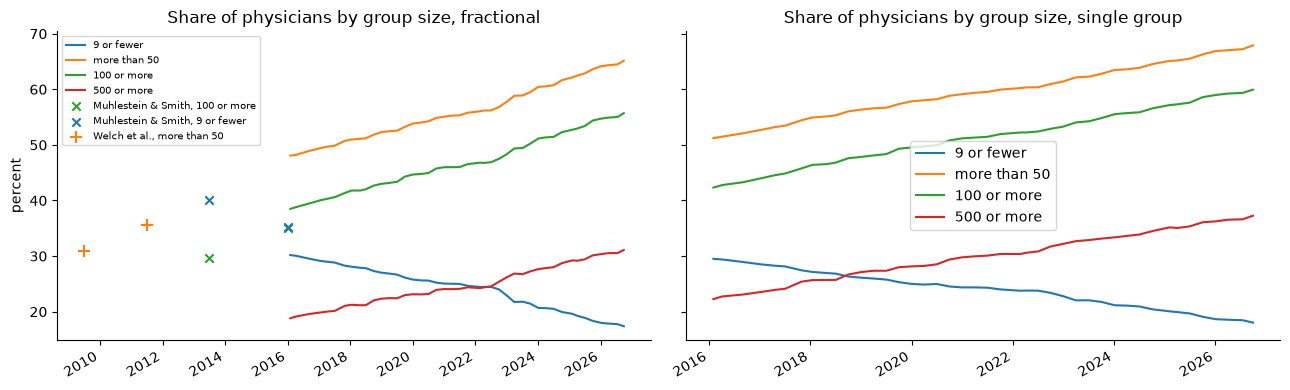

,as_of_date,weighting,9 or fewer,more than 50,100 or more,500 or more
0,2016-02-01,fractional,30.2,48.1,38.5,18.8
1,2016-02-01,single group,29.5,51.2,42.3,22.3
24,2019-04-01,fractional,26.9,52.5,43.2,22.4
25,2019-04-01,single group,26.0,56.6,48.1,27.4
48,2022-04-12,fractional,24.5,56.2,46.8,24.4
49,2022-04-12,single group,23.8,60.3,52.2,30.6
72,2025-04-01,fractional,19.3,62.5,52.9,29.2
73,2025-04-01,single group,19.9,65.2,57.3,35.1
84,2026-09-29,fractional,17.4,65.1,55.7,31.1
85,2026-09-29,single group,18.0,67.9,59.9,37.3


In [7]:
shares = con.sql("SELECT * FROM size_shares ORDER BY as_of_date, weighting").df()
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (w, d) in zip(axes, shares.groupby("weighting")):
    d.set_index("as_of_date").drop(columns="weighting").plot(ax=ax, title=f"Share of physicians by group size, {w}")
    ax.set_xlabel(""); ax.set_ylabel("percent")
axes[0].scatter(pd.to_datetime(["2013-06-30", "2015-12-31"]), [29.6, 35.1], marker="x", color="C2", zorder=5,
                label="Muhlestein & Smith, 100 or more")
axes[0].scatter(pd.to_datetime(["2013-06-30", "2015-12-31"]), [40.1, 35.3], marker="x", color="C0", zorder=5,
                label="Muhlestein & Smith, 9 or fewer")
axes[0].scatter(pd.to_datetime(["2009-06-30", "2011-06-30"]), [30.9, 35.6], marker="+", s=80, color="C1", zorder=5,
                label="Welch et al., more than 50")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
shares[shares.as_of_date.isin(shares.as_of_date.unique()[[0, 12, 24, 36, -1]])].round(1)

In [8]:
con.sql("""
SELECT e.as_of_date,
       100 * sum(1.0 / e.k) FILTER (WHERE g.headcount >= 100) / sum(1.0 / e.k) AS "100 or more, headcount size",
       100 * sum(1.0 / e.k) FILTER (WHERE g.physicians >= 100) / sum(1.0 / e.k) AS "100 or more, fractional size",
       100 * sum(1.0 / e.k) FILTER (WHERE g.headcount <= 9) / sum(1.0 / e.k) AS "9 or fewer, headcount size",
       100 * sum(1.0 / e.k) FILTER (WHERE g.physicians < 10) / sum(1.0 / e.k) AS "9 or fewer, fractional size",
       sum(g.headcount) / sum(g.physicians) AS headcount_per_physician
FROM physician_edge e
JOIN group_size g USING (as_of_date, organization_pac_id)
WHERE e.as_of_date IN (SELECT as_of_date FROM quarters ORDER BY as_of_date LIMIT 1)
   OR e.as_of_date IN (SELECT as_of_date FROM quarters ORDER BY as_of_date DESC LIMIT 1)
GROUP BY 1 ORDER BY 1
""").df().round(2)

,as_of_date,"100 or more, headcount size","100 or more, fractional size","9 or fewer, headcount size","9 or fewer, fractional size",headcount_per_physician
0,2016-02-01,45.60,38.49,23.75,30.19,1.34
1,2026-09-29,67.28,55.71,12.60,17.39,1.73


**The direction replicates and continues, and the levels come close.** The share of physicians in groups of 100 or more rises from 38.5 to 55.7 percent fractional (42.3 to 59.9 single group) between February 2016 and September 2026, and the share in groups of nine or fewer falls from 30.2 to 17.4 percent. The trend is steady, with one extra step in the 2022-23 clean-up quarters, where small organizations left the file.

Against Muhlestein and Smith's December 2015 figures, 35.1 percent in groups of 100 or more and 35.3 percent in groups of nine or fewer, the graph's February 2016 is 3.4 points higher at the top and 5.1 points lower at the bottom. Sized by headcount, as a first version of this notebook did, the gaps were 10.5 and 11.5 points (the table just above): a physician with several reassignments was counted in every one of their groups, which inflates large groups most, and headcounts per physician grew from 1.34 to 1.73 over the decade. Section 6 confirms the fractional size against AHRQ's MD-PPAS counts on the same tax ids.

What remains of the gap has three known sources that public data cannot remove. Physician Compare showed a reassignment only if the pair had billed in the past 12 months, or the reassignment was less than six months old; the raw PPEF keeps every active reassignment. The papers' physicians are the ones with Medicare claims, while ours are everyone with a physician taxonomy and a reassignment. And Muhlestein and Smith's appendix, which defines their counting, was not available to us. The mean number of reassignments per physician with any rises by a third, from 1.6 to 2.1 (the coverage table at the start of this section), and the share with exactly one falls from 65 to 53 percent, consistent both with stale reassignments piling up and with physicians really billing through more organizations (telehealth groups, hospitalist and locum companies).

Muhlestein and Smith report the shift as larger for primary care physicians than for specialists. The same split, by Medicare specialty:


In [9]:
con.execute("""
CREATE TABLE physician_specialty AS
SELECT as_of_date, pac_id, practice_zip5, practice_state,
       CASE WHEN list_has_any(provider_type_codes, ['14-01', '14-08', '14-11', '14-37', '14-38']) THEN 'primary care'
            WHEN list_contains(provider_type_codes, '14-06') THEN 'cardiology'
            WHEN list_has_any(provider_type_codes, ['14-83', '14-90', '14-92']) THEN 'oncology'
            WHEN list_contains(provider_type_codes, '14-20') THEN 'orthopedic surgery'
            WHEN list_contains(provider_type_codes, '14-16') THEN 'obstetrics/gynecology'
            WHEN list_contains(provider_type_codes, '14-10') THEN 'gastroenterology'
            WHEN list_contains(provider_type_codes, '14-07') THEN 'dermatology'
       END AS specialty,
       list_has_any(provider_type_codes, ['14-01', '14-08', '14-11', '14-37', '14-38']) AS primary_care
FROM physician_q
""")
pc = con.sql("""
SELECT e.as_of_date, CASE WHEN s.primary_care THEN 'primary care' ELSE 'specialist' END AS physicians,
       100 * sum(1.0 / e.k) FILTER (WHERE g.physicians >= 100) / sum(1.0 / e.k) AS "100 or more",
       100 * sum(1.0 / e.k) FILTER (WHERE g.physicians < 10) / sum(1.0 / e.k) AS "9 or fewer"
FROM physician_edge e
JOIN group_size g USING (as_of_date, organization_pac_id)
JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
GROUP BY ALL ORDER BY 1, 2
""").df()
pc.pivot(index="as_of_date", columns="physicians").iloc[[0, 12, 24, 36, -1]].round(1)

100 or more              9 or fewer           
physicians primary care specialist primary care specialist
as_of_date                                                
2016-02-01         42.0       36.5         27.7       31.5
2019-04-01         45.8       41.8         25.4       27.6
2022-04-12         49.1       45.6         23.2       25.1
2025-04-01         55.1       51.8         18.7       19.6
2026-09-29         57.4       54.9         17.2       17.5

Primary care physicians start in larger groups than specialists (42 against 37 percent in groups of 100 or more), but over the decade specialists gain more (18 points against 15) and leave small groups faster (14 points against 10). Muhlestein and Smith's finding that the shift was larger in primary care held for 2013 to 2015; in this graph it does not hold for 2016 to 2026.

## 4. Market concentration: an HHI that public data cannot pin down

Capps, Dranove and Ody found 22 percent of physician markets highly concentrated in 2013 under the federal merger guidelines, and Fulton found primary care HHIs rising by about 29 percent between 2010 and 2016. Both papers used claims or vendor data to assign each physician to one firm and rolled practices up to the systems that own them; neither paper's market definition was available to us. The stated substitute: a market is a Dartmouth hospital referral region (by the physician's NPPES practice ZIP, `reference/zip_hrr_2019.csv`) times a specialty group, a firm is an organization associate id, the share is the firm's share of the market's physicians, and a market is highly concentrated when its HHI exceeds 2,500 (the 2010 Horizontal Merger Guidelines; the 2023 guidelines lowered it to 1,800).

The same two weightings as in section 3:

In [10]:
con.execute("""
CREATE TABLE market_hhi AS
WITH m AS (
    SELECT e.as_of_date, w.weighting, h.hrr, s.specialty, e.organization_pac_id, sum(w.wt) AS physicians
    FROM physician_edge e
    JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
    JOIN hrr h ON h.zip5 = s.practice_zip5
    CROSS JOIN LATERAL (VALUES ('fractional', 1.0 / e.k), ('single group', CASE WHEN e.k = 1 THEN 1.0 END)) w(weighting, wt)
    WHERE s.specialty IS NOT NULL AND w.wt IS NOT NULL
    GROUP BY ALL)
SELECT as_of_date, weighting, hrr, specialty, sum(physicians) AS physicians,
       sum(power(100 * physicians, 2)) / power(sum(physicians), 2) AS hhi
FROM m GROUP BY ALL
""")
hhi = con.sql("""
SELECT year(as_of_date) AS year, weighting, specialty,
       100 * avg(CAST(hhi > 2500 AS INTEGER)) AS pct_highly_concentrated,
       median(hhi) AS median_hhi
FROM market_hhi
WHERE month(as_of_date) <= 2 AND year(as_of_date) IN (2016, 2018, 2020, 2022, 2024, 2026)
GROUP BY ALL ORDER BY specialty, weighting, year
""").df()
hhi.pivot(index=["specialty", "weighting"], columns="year", values="pct_highly_concentrated").round(1)

year                                2016  2018  2020  2022  2024  2026
specialty             weighting                                       
cardiology            fractional    21.6  18.6  17.0  15.0  14.7  15.7
                      single group  57.0  58.6  58.8  56.9  58.7  58.1
dermatology           fractional    31.7  29.7  28.4  24.2  25.2  26.5
                      single group  41.4  39.3  40.5  39.0  43.9  44.1
gastroenterology      fractional    40.8  38.2  35.0  32.7  30.4  30.4
                      single group  56.1  56.8  58.2  59.1  61.3  64.3
obstetrics/gynecology fractional    12.1   9.2   8.2   7.8   8.2   7.5
                      single group  23.5  25.8  26.1  28.1  30.1  34.4
oncology              fractional    34.4  33.7  31.4  26.5  25.5  25.8
                      single group  61.2  64.3  63.4  63.8  67.0  68.9
orthopedic surgery    fractional    22.9  20.3  19.6  17.3  16.3  18.3
                      single group  34.6  35.6  39.5  36.7  40.7  44.8
primary care          fractional     2.0   1.6   2.0   1.3   1.6   2.0
                      single group   8.5   8.8   8.5   7.8   8.2   9.8

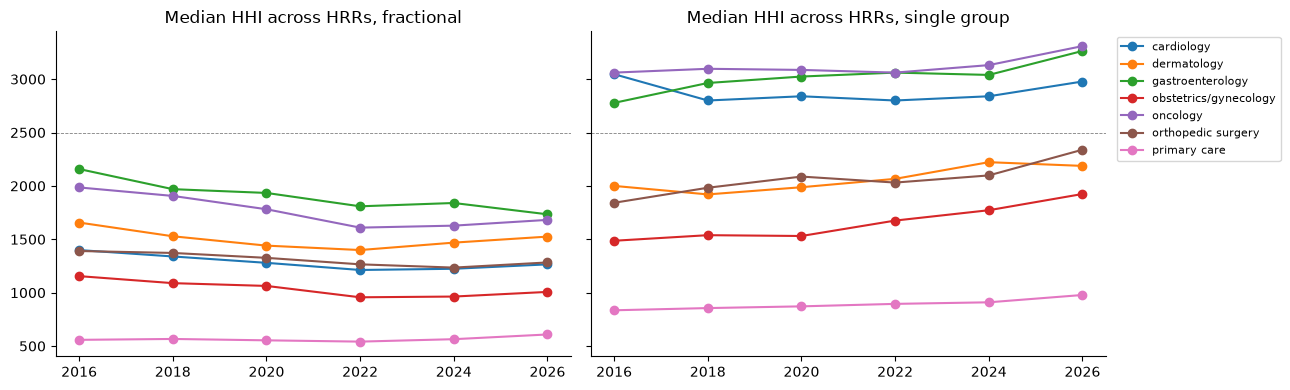

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (w, d) in zip(axes, hhi.groupby("weighting")):
    d.pivot(index="year", columns="specialty", values="median_hhi").plot(ax=ax, marker="o", title=f"Median HHI across HRRs, {w}")
    ax.axhline(2500, color="grey", lw=0.6, ls="--"); ax.set_xlabel("")
axes[0].get_legend().remove()
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**The two weightings disagree on the sign of the trend.** With fractional shares, the share of highly concentrated markets *falls* in every specialty but primary care, where it is flat. Among single-group physicians it is flat in primary care and cardiology and *rises* in the other five specialties, the direction of the literature. The cause is visible in section 3: as physicians add reassignments, fractional shares spread each of them over more firms, and the HHI falls mechanically, whether the extra reassignments are real or stale. The single-group sample has the opposite problem. It is half the physicians, and it is chosen by the very behavior (billing through one firm) that differs between small practices and large systems.

So the graph replicates the group-size trend but not an HHI trend. A defensible physician-market HHI needs what the papers had and the public files do not: a volume measure to choose each physician's main firm, and an ownership roll-up from tax ids to systems. The levels are not comparable to Capps, Dranove and Ody either way, because their firms are systems and ours are tax ids, which understates concentration wherever a system bills through several tax ids.

Section 4b supplies the first of the two from a second public source.

## 4b. Choosing the main group with Medicaid volume

The rule both papers use needs each physician's billing by firm. The public Medicare files do not have it, but HHS's public extract of Medicaid claims (T-MSIS, on [opendata.hhs.gov](https://opendata.hhs.gov/)) does for Medicaid: paid amounts by billing NPI, servicing NPI, HCPCS code and month, 2018 to 2024. A billing NPI belongs to an organization associate id in the graph, and a servicing NPI to a practitioner, so each reassignment edge can be given the Medicaid dollars it carried.

The rule, in the papers' terms:

* **Window.** Medicaid paid in calendar year `Y` ranks the reassignments in force on the first graph quarter on or after 31 December `Y`, a 12-month look-back like Physician Compare's billing filter.
* **Plurality.** A physician with one reassignment keeps it. A physician with several is assigned to the one with the most Medicaid paid, as Welch et al. and Capps, Dranove and Ody assign by plurality of charges. A physician with several and no Medicaid paid on any is left out.
* **Majority.** A stricter variant keeps only assignments where the main group carries at least half of the physician's Medicaid paid across their reassignments, in the spirit of Luo et al.'s "primarily".
* **States.** Medicaid billing reaches the graph unevenly by state (the cell below). States where fewer than a quarter of multi-group physicians can be assigned, pooled over the seven quarters and counting states with at least 1,000 such physician-quarters, are left out of every weighting in this section, as Zhu et al. dropped state-years with unusable T-MSIS data. The 25 percent line is ours; the paper's exclusions are in its appendix, which was not available to us.

Medicaid volume is not Medicare volume. A physician's main Medicaid group can differ from their main Medicare group, specialties that see few Medicaid patients are thin, and the extract drops every billing NPI, servicing NPI, code and month with fewer than 12 patients or claim lines. Suppression matters here only when all of a physician's Medicaid billing is in small cells (then they are left out) or when it spreads a group's volume over many small cells (then a smaller group can win).

`graph-build --medicaid` reads the Medicaid source's `medicaid_spending` table (`load --source-name medicaid`) and writes the volume of each edge and the main group by this rule:

`src/healthcare_ledger/derived/sql/medicaid_volume.sql`, written to `medicaid_volume.parquet`:

```sql
-- medicaid_volume: the Medicaid dollars an organization's NPIs billed for a physician's NPI in calendar year Y
-- (HHS's Medicaid spending extract, self-billing excluded), on the first quarter on or after 31 December Y
WITH y AS (SELECT DISTINCT year(month) AS y FROM medicaid_spending),
q AS (SELECT y.y, min(q.as_of_date) AS as_of_date FROM y JOIN quarters q ON q.as_of_date >= make_date(y.y, 12, 31) GROUP BY 1),
pr AS (SELECT q.y, q.as_of_date, p.pac_id, p.npi FROM q
       JOIN practitioner p ON p.effective_date <= q.as_of_date AND (p.end_date IS NULL OR p.end_date > q.as_of_date)),
og AS (SELECT q.as_of_date, o.pac_id, unnest(o.npis) AS npi FROM q
       JOIN organization o ON o.effective_date <= q.as_of_date AND (o.end_date IS NULL OR o.end_date > q.as_of_date)),
s AS (SELECT year(month) AS y, billing_npi, servicing_npi, sum(paid) AS paid
      FROM medicaid_spending WHERE billing_npi <> servicing_npi GROUP BY ALL)
SELECT pr.as_of_date, pr.pac_id AS practitioner_pac_id, og.pac_id AS organization_pac_id, sum(s.paid) AS medicaid_paid
FROM s
JOIN pr ON pr.y = s.y AND pr.npi = s.servicing_npi
JOIN og ON og.as_of_date = pr.as_of_date AND og.npi = s.billing_npi
GROUP BY ALL
```

`src/healthcare_ledger/derived/sql/main_group.sql`, written to `main_group.parquet`:

```sql
-- main_group: each physician's group by plurality of Medicaid volume on the quarters medicaid_volume covers
-- (ties broken by organization PAC id); a physician with one reassignment keeps it; share is that group's
-- part of the physician's Medicaid paid (1 for a single reassignment)
WITH e AS (
    SELECT e.as_of_date, e.practitioner_pac_id, e.organization_pac_id, e.k, coalesce(v.medicaid_paid, 0) AS paid,
           sum(coalesce(v.medicaid_paid, 0)) OVER (PARTITION BY e.as_of_date, e.practitioner_pac_id) AS physician_paid
    FROM physician_edge e
    LEFT JOIN medicaid_volume v USING (as_of_date, practitioner_pac_id, organization_pac_id)
    WHERE e.as_of_date IN (SELECT DISTINCT as_of_date FROM medicaid_volume))
SELECT as_of_date, practitioner_pac_id, organization_pac_id, k,
       CASE WHEN k = 1 THEN 1.0 ELSE paid / physician_paid END AS share
FROM e
WHERE k = 1 OR paid > 0
QUALIFY row_number() OVER (PARTITION BY as_of_date, practitioner_pac_id ORDER BY paid DESC, organization_pac_id) = 1
```

In [12]:
# the Medicaid volume of each edge and each physician's main group, written by graph-build --medicaid (the SQL is
# above); without it, section 4b runs on empty tables
if "main_group" not in manifest["tables"]:
    con.execute("CREATE TABLE medicaid_volume (as_of_date DATE, practitioner_pac_id VARCHAR, organization_pac_id VARCHAR, "
                "medicaid_paid DOUBLE)")
    con.execute("CREATE TABLE main_group (as_of_date DATE, practitioner_pac_id VARCHAR, organization_pac_id VARCHAR, "
                "k BIGINT, share DOUBLE)")
con.execute("""
CREATE TABLE state_coverage AS
SELECT s.practice_state,
       count(DISTINCT (e.as_of_date, e.practitioner_pac_id)) AS multi_group_physicians,
       100 * count(DISTINCT (m.as_of_date, m.practitioner_pac_id)) / count(DISTINCT (e.as_of_date, e.practitioner_pac_id)) AS pct_assigned,
       pct_assigned < 25 AND multi_group_physicians >= 1000 AS screened_out
FROM physician_edge e
JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
LEFT JOIN main_group m ON m.as_of_date = e.as_of_date AND m.practitioner_pac_id = e.practitioner_pac_id
WHERE e.k > 1 AND e.as_of_date IN (SELECT DISTINCT as_of_date FROM main_group)
GROUP BY 1
""")
cov = con.sql("""
WITH two AS (
    SELECT v.as_of_date, v.practitioner_pac_id
    FROM medicaid_volume v
    SEMI JOIN physician_edge e USING (as_of_date, practitioner_pac_id, organization_pac_id)
    GROUP BY ALL HAVING count(*) >= 2)
SELECT e.as_of_date, count(DISTINCT e.practitioner_pac_id) FILTER (WHERE e.k > 1) AS multi_group_physicians,
       count(DISTINCT m.practitioner_pac_id) FILTER (WHERE m.k > 1) AS assigned_plurality,
       count(DISTINCT m.practitioner_pac_id) FILTER (WHERE m.k > 1 AND m.share >= 0.5) AS assigned_majority,
       count(DISTINCT t.practitioner_pac_id) AS paid_by_two_or_more
FROM physician_edge e
LEFT JOIN main_group m USING (as_of_date, practitioner_pac_id)
LEFT JOIN two t USING (as_of_date, practitioner_pac_id)
WHERE e.as_of_date IN (SELECT DISTINCT as_of_date FROM main_group)
GROUP BY 1 ORDER BY 1
""").df().set_index("as_of_date")
cov["pct_plurality"] = 100 * cov.assigned_plurality / cov.multi_group_physicians
print("states screened out:", con.sql("SELECT string_agg(practice_state || ' ' || round(pct_assigned)::INT || '%', ', ' ORDER BY pct_assigned) FROM state_coverage WHERE screened_out").fetchone()[0])
cov.round(1)

states screened out: MI 9%, IL 10%, SD 18%, UT 21%, GA 23%, DE 24%


,multi_group_physicians,assigned_plurality,assigned_majority,paid_by_two_or_more,pct_plurality
as_of_date,,,,,
2018-12-31,272535,109368,108941,21363,40.1
2020-01-02,290546,119528,119005,23168,41.1
2020-12-31,318468,136786,136278,24225,43.0
2022-02-24,351822,157268,156675,27522,44.7
2023-03-31,362749,162571,161858,29698,44.8
2024-01-05,373849,168294,167382,32019,45.0
2025-02-03,390897,160667,159957,26511,41.1


Group size under the main-group rule, next to the two weightings of section 3 on the same quarters and states:

In [13]:
con.execute("""
CREATE TABLE weighted_edge AS
WITH e AS (
    SELECT e.as_of_date, e.practitioner_pac_id, e.organization_pac_id, e.k, m.share
    FROM physician_edge e
    JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
    LEFT JOIN main_group m ON m.as_of_date = e.as_of_date AND m.practitioner_pac_id = e.practitioner_pac_id
                          AND m.organization_pac_id = e.organization_pac_id
    WHERE e.as_of_date IN (SELECT DISTINCT as_of_date FROM main_group)
      AND s.practice_state NOT IN (SELECT practice_state FROM state_coverage WHERE screened_out))
SELECT e.as_of_date, e.practitioner_pac_id, e.organization_pac_id, w.weighting, w.wt
FROM e
CROSS JOIN LATERAL (VALUES ('fractional', 1.0 / e.k),
                           ('single group', CASE WHEN e.k = 1 THEN 1.0 END),
                           ('Medicaid plurality', CASE WHEN e.share IS NOT NULL THEN 1.0 END),
                           ('Medicaid majority', CASE WHEN e.share >= 0.5 THEN 1.0 END)) w(weighting, wt)
WHERE w.wt IS NOT NULL
""")
weighted_sizes = con.sql("""
SELECT e.as_of_date, e.weighting,
       100 * sum(e.wt) FILTER (WHERE g.physicians < 10) / sum(e.wt) AS "9 or fewer",
       100 * sum(e.wt) FILTER (WHERE g.physicians >= 100) / sum(e.wt) AS "100 or more"
FROM weighted_edge e
JOIN group_size g USING (as_of_date, organization_pac_id)
GROUP BY ALL ORDER BY 1, 2
""").df()
weighted_sizes.pivot(index="as_of_date", columns="weighting").round(1)

9 or fewer                                                  100 or more                                           
weighting  Medicaid majority Medicaid plurality fractional single group Medicaid majority Medicaid plurality fractional single group
as_of_date                                                                                                                          
2018-12-31              26.5               26.5       26.7         25.9              44.8               44.8       43.3         48.0
2020-01-02              25.4               25.4       25.5         24.8              46.2               46.2       44.8         49.6
2020-12-31              24.6               24.6       24.8         24.1              47.6               47.6       46.2         51.4
2022-02-24              23.8               23.9       24.2         23.5              48.6               48.6       47.1         52.4
2023-03-31              22.1               22.1       21.5         21.9              50.4               50.3       49.6         54.2
2024-01-05              21.0               21.0       20.5         21.0              52.2               52.1       51.5         55.7
2025-02-03              20.0               20.0       19.4         19.9              53.9               53.9       53.1         57.5

And the HHI of section 4 under all four weightings:

In [14]:
con.execute("""
CREATE TABLE weighted_hhi AS
WITH m AS (
    SELECT e.as_of_date, e.weighting, h.hrr, s.specialty, e.organization_pac_id, sum(e.wt) AS physicians
    FROM weighted_edge e
    JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
    JOIN hrr h ON h.zip5 = s.practice_zip5
    WHERE s.specialty IS NOT NULL
    GROUP BY ALL)
SELECT as_of_date, weighting, hrr, specialty, sum(physicians) AS physicians,
       sum(power(100 * physicians, 2)) / power(sum(physicians), 2) AS hhi
FROM m GROUP BY ALL
""")
whhi = con.sql("""
SELECT as_of_date, weighting, specialty, 100 * avg(CAST(hhi > 2500 AS INTEGER)) AS pct_highly_concentrated, median(hhi) AS median_hhi
FROM weighted_hhi GROUP BY ALL ORDER BY ALL
""").df()
first, last = whhi.as_of_date.min(), whhi.as_of_date.max()
change = whhi[whhi.as_of_date.isin([first, last])].pivot(index=["specialty", "weighting"], columns="as_of_date", values="pct_highly_concentrated")
change.columns = [str(c.date()) for c in change.columns]
change["change"] = change.iloc[:, 1] - change.iloc[:, 0]
change.round(1)

2018-12-31  2025-02-03  change
specialty             weighting                                         
cardiology            Medicaid majority         47.2        46.7    -0.5
                      Medicaid plurality        47.2        46.7    -0.5
                      fractional                17.8        13.7    -4.1
                      single group              58.9        60.5     1.5
dermatology           Medicaid majority         38.1        39.3     1.1
                      Medicaid plurality        38.1        39.3     1.1
                      fractional                32.5        24.0    -8.5
                      single group              40.9        45.5     4.6
gastroenterology      Medicaid majority         51.9        52.2     0.4
                      Medicaid plurality        51.9        52.2     0.4
                      fractional                37.9        31.2    -6.7
                      single group              57.4        63.6     6.2
obstetrics/gynecology Medicaid majority         22.4        24.3     1.8
                      Medicaid plurality        22.4        24.3     1.8
                      fractional                 9.9         9.2    -0.7
                      single group              30.9        33.0     2.1
oncology              Medicaid majority         57.6        58.7     1.1
                      Medicaid plurality        57.6        58.7     1.1
                      fractional                34.4        29.3    -5.2
                      single group              63.3        70.2     6.9
orthopedic surgery    Medicaid majority         34.2        33.8    -0.4
                      Medicaid plurality        34.2        33.8    -0.4
                      fractional                21.0        16.5    -4.4
                      single group              39.0        43.9     4.9
primary care          Medicaid majority          7.6         6.9    -0.7
                      Medicaid plurality         7.6         6.9    -0.7
                      fractional                 3.6         3.6     0.0
                      single group               9.7        11.2     1.5

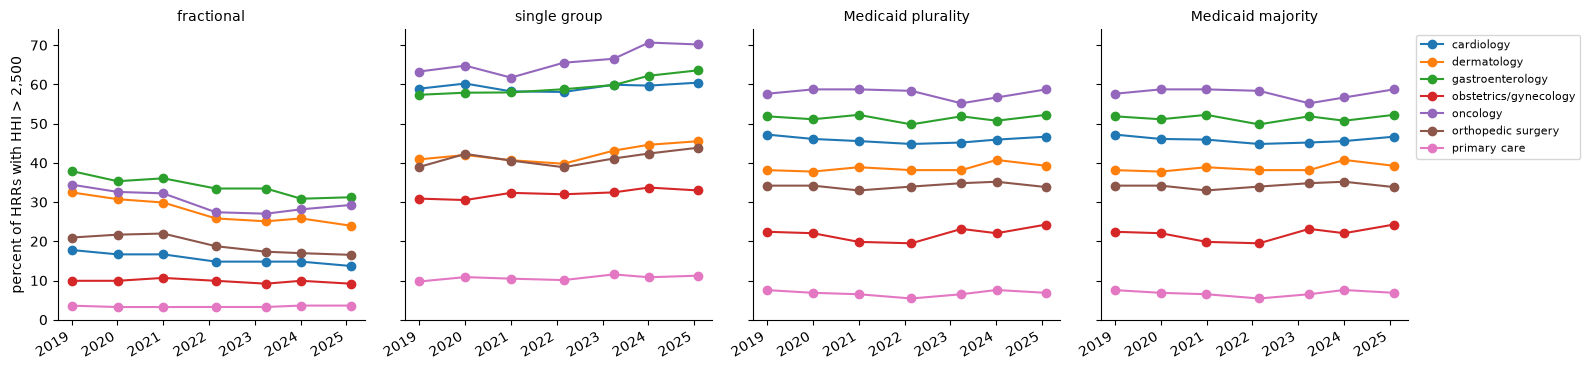

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, w in zip(axes, ["fractional", "single group", "Medicaid plurality", "Medicaid majority"]):
    d = whhi[whhi.weighting == w]
    if len(d):
        d.pivot(index="as_of_date", columns="specialty", values="pct_highly_concentrated").plot(ax=ax, marker="o", legend=False)
    ax.set_title(w, fontsize=10); ax.set_xlabel("")
axes[0].set_ylabel("percent of HRRs with HHI > 2,500")
if axes[-1].lines:
    axes[-1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**Medicaid volume can rank the groups of four in ten multi-group physicians**: 40 to 45 percent each quarter, out of 270,000 to 390,000. The rest bill Medicaid only under their own NPI, in suppressed cells, in states the extract misses, or not at all. Majority and plurality give nearly the same answer, because only 21,000 to 32,000 physicians a quarter have Medicaid volume on two or more of their groups. For most multi-group physicians the Medicaid dollars land on exactly one of their Medicare reassignments, and the others carry none. That fits the stale-reassignment reading of section 3, but Medicaid billing alone cannot prove it: a reassignment can carry Medicare claims and no Medicaid claims.

**Group size does not depend on the weighting.** Between the end of 2018 and February 2025 the share of physicians in groups of 100 or more rises from 44.8 to 53.9 percent under the Medicaid rule, against 43.3 to 53.1 fractional and 48.0 to 57.5 single group. The trend of section 3 holds under the papers' own assignment rule, and the Medicaid rule sits within two points of the fractional weighting. How a physician is weighted barely moves the level; how a group is sized does (section 3).

**The HHI trend is flat under the papers' rule.** With each physician in their Medicaid main group, the share of highly concentrated markets moves by less than two points in every specialty between 2018 and 2025: down 0.7 in primary care and 0.5 in cardiology, up 1.8 in obstetrics and gynecology and 1.1 in dermatology and oncology. The two substitutes of section 4 bracket it: fractional falls in six of seven specialties (by up to 8.5 points), single group rises in all seven (by up to 6.9). The bracketing is what section 4's explanation predicts. Fractional shares fall mechanically as physicians add reassignments. The single-group sample loses exactly the physicians who add groups. The Medicaid rule keeps those physicians and puts each in one firm, and its trend lies between the two substitutes, near zero.

So at the tax-id level, on the papers' assignment rule, physician markets by HRR and specialty were about as concentrated in early 2025 as at the end of 2018. Physicians moved into large groups over the same years without raising market HHIs; the graph does not say which markets absorbed the growth, and that is the next question to ask of it. This is not a test of Fulton's or Capps, Dranove and Ody's findings. Their windows end in 2016 and 2013, their firms are systems, and the Medicaid rule covers only the multi-group physicians who bill Medicaid through a group, outside the six screened states. Section 7 computes the system-level HHI.

## 5. Physicians billing through hospital entities: a lower bound on vertical integration

Luo et al. (2024) call a physician vertically integrated when they bill primarily through a hospital-related tax id. They find the share rising from 19 percent in 1999 to 43 percent in 2019, and they show that the simplest version, counting only tax ids that themselves bill as a hospital, finds about 30 percent of the hospital-related tax ids their full method finds. That simple version is the one the graph supports: an organization is a hospital entity when its associate id holds a hospital, critical access hospital or rural emergency hospital enrollment, or a Part B hospital department enrollment. Shown with both weightings, plus "any": a physician with at least one reassignment to a hospital entity.

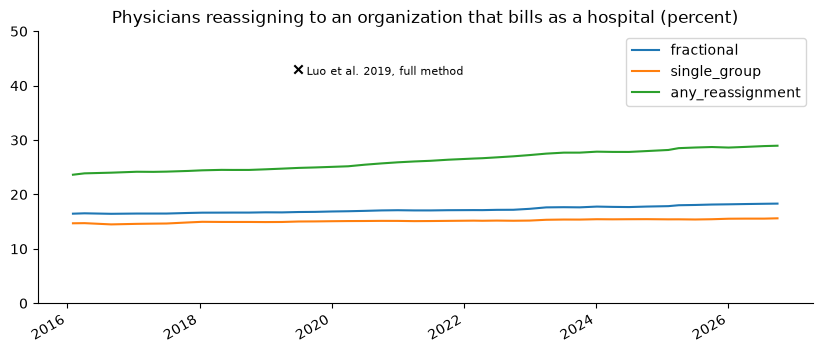

,fractional,single_group,any_reassignment
as_of_date,,,
2016-02-01,16.5,14.7,23.6
2019-04-01,16.7,14.9,24.7
2022-04-12,17.1,15.2,26.7
2025-04-01,18.0,15.4,28.5
2026-09-29,18.3,15.6,29.0


In [16]:
vi = con.sql("""
WITH oq AS (
    SELECT q.as_of_date, o.pac_id, o.hospital
    FROM quarters q
    JOIN organization o ON o.effective_date <= q.as_of_date AND (o.end_date IS NULL OR o.end_date > q.as_of_date))
SELECT e.as_of_date,
       100 * sum(1.0 / e.k) FILTER (WHERE oq.hospital) / sum(1.0 / e.k) AS fractional,
       100 * count(*) FILTER (WHERE oq.hospital AND e.k = 1) / count(*) FILTER (WHERE e.k = 1) AS single_group,
       100 * count(DISTINCT e.practitioner_pac_id) FILTER (WHERE oq.hospital) / count(DISTINCT e.practitioner_pac_id) AS any_reassignment
FROM physician_edge e
JOIN oq ON oq.as_of_date = e.as_of_date AND oq.pac_id = e.organization_pac_id
GROUP BY 1 ORDER BY 1
""").df().set_index("as_of_date")
ax = vi.plot(title="Physicians reassigning to an organization that bills as a hospital (percent)")
ax.scatter(pd.to_datetime(["2019-06-30"]), [43], marker="x", color="k", zorder=5)
ax.annotate("Luo et al. 2019, full method", (pd.Timestamp("2019-06-30"), 43), textcoords="offset points", xytext=(6, -4), fontsize=8)
ax.set_xlabel(""); ax.set_ylim(0, 50); plt.show()
vi.iloc[[0, 12, 24, 36, -1]].round(1)

In [17]:
con.sql("""
WITH oq AS (
    SELECT q.as_of_date, o.pac_id, o.hospital
    FROM quarters q
    JOIN organization o ON o.effective_date <= q.as_of_date AND (o.end_date IS NULL OR o.end_date > q.as_of_date))
SELECT s.specialty,
       100 * sum(1.0 / e.k) FILTER (WHERE oq.hospital AND year(e.as_of_date) = 2016) / sum(1.0 / e.k) FILTER (WHERE year(e.as_of_date) = 2016) AS pct_2016,
       100 * sum(1.0 / e.k) FILTER (WHERE oq.hospital AND year(e.as_of_date) = 2026) / sum(1.0 / e.k) FILTER (WHERE year(e.as_of_date) = 2026) AS pct_2026
FROM physician_edge e
JOIN oq ON oq.as_of_date = e.as_of_date AND oq.pac_id = e.organization_pac_id
JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
WHERE month(e.as_of_date) <= 2 AND year(e.as_of_date) IN (2016, 2026) AND s.specialty IS NOT NULL
GROUP BY 1 ORDER BY pct_2026 DESC
""").df().round(1)

,specialty,pct_2016,pct_2026
0,cardiology,22.5,23.7
1,oncology,18.9,22.7
2,primary care,18.1,19.0
3,orthopedic surgery,12.8,17.4
4,obstetrics/gynecology,14.9,16.7
5,gastroenterology,12.0,15.4
6,dermatology,7.2,7.3


The share rises slowly and steadily under every weighting (16.5 to 18.3 percent fractional, 23.6 to 29.0 percent with any hospital reassignment), and its level, a quarter of physicians with any hospital reassignment in 2019, sits below Luo et al.'s 43 percent, as a basic-tax-id measure must. By specialty it is highest in cardiology and oncology, as Nikpay, Richards and Penson (*Health Affairs* 2018) found with vendor data, but it moves by one to four points over the decade, far less than the 34 points they report for 2007 to 2017; most of the integration they measured does not run through a hospital's own tax id. The literature's warnings apply in full. Hospitals buy practices and keep billing through the practice's own tax id, or through a system's physician-group entity that has no hospital enrollment, and the graph cannot see either. Treat this series as a floor whose movement, not level, carries information. Section 6 replaces it with system membership.


## 6. Health systems: the AHRQ Compendium

AHRQ's Compendium of U.S. Health Systems (2016, 2018 and 2020-2023; there is no 2017 or 2019 edition) lists every US health system with at least one general acute hospital and a group of physicians under common ownership or management. It was built at NBER and Mathematica from IRS Form 990 Schedules A, H and R, the IRS Business Master File, PECOS chain home offices, SEC 10-K exhibits, M&A databases and Medicare hospital-outpatient billing: the ownership-network method Luo et al. use for their full measure. AHRQ publishes its linkage files: hospitals, nursing homes and home health agencies by CCN, and physician group practices with their **PECOS associate ids**. `healthcare-ledger download --source-name ahrq` fetches the pinned files, `load --source-name ahrq` puts them in the warehouse and `graph-build --compendium` turns them into the `system` and `system_link` tables.

The group practice files (2016, 2018, 2020-2022) list every tax id with two or more physicians in that year's MD-PPAS, which puts each physician in the one tax id billing the plurality of their Medicare Part B lines, and give that physician count. That is the claims-based main-group rule the papers use and the PPEF lacks, so for those years it scores the graph directly: on the same tax ids, the share of physicians in a system and in groups of 100 or more, by MD-PPAS and by the graph.


In [18]:
con.execute("""
CREATE TABLE compendium_q AS
SELECT y.year, arg_min(q.as_of_date, abs(date_diff('day', q.as_of_date, make_date(y.year, 7, 1)))) AS as_of_date
FROM (SELECT DISTINCT year FROM system_link) y CROSS JOIN quarters q
GROUP BY 1
""")
con.execute("""
CREATE TABLE ahrq_group AS
SELECT year, compendium_id, any_value(health_sys_id) AS health_sys_id, any_value(md_ppas_physicians) AS md_ppas
FROM system_link WHERE node_type = 'organization' AND via = 'group practice file' GROUP BY 1, 2
""")
con.execute("""
CREATE TABLE ahrq_edge AS
SELECT c.year, e.practitioner_pac_id, e.organization_pac_id, e.k, l.compendium_id, l.health_sys_id
FROM compendium_q c
JOIN physician_edge e ON e.as_of_date = c.as_of_date
JOIN system_link l ON l.year = c.year AND l.node_type = 'organization' AND l.node_id = e.organization_pac_id
                  AND l.via = 'group practice file'
""")
ahrq_check = con.sql("""
WITH found AS (SELECT DISTINCT year, compendium_id FROM ahrq_edge),
size AS (SELECT year, compendium_id, count(DISTINCT practitioner_pac_id) AS headcount, sum(1.0 / k) AS physicians
         FROM ahrq_edge GROUP BY 1, 2),
-- each physician once, over their edges to AHRQ-listed tax ids
phys AS (SELECT year, practitioner_pac_id, avg((health_sys_id IS NOT NULL)::INT) AS frac_sys,
                bool_or(health_sys_id IS NOT NULL) AS any_sys, max(k) AS k
         FROM ahrq_edge GROUP BY 1, 2),
w AS (SELECT e.year, 1.0 / e.k AS w, s.headcount, s.physicians FROM ahrq_edge e JOIN size s USING (year, compendium_id))
SELECT g.year,
       count(*) AS ahrq_tax_ids,
       100 * avg((f.compendium_id IS NOT NULL)::INT) AS pct_tax_ids_found,
       100 * sum(g.md_ppas) FILTER (WHERE f.compendium_id IS NOT NULL) / sum(g.md_ppas) AS pct_md_ppas_physicians_found,
       100 * sum(g.md_ppas) FILTER (WHERE g.health_sys_id IS NOT NULL) / sum(g.md_ppas) AS system_md_ppas,
       (SELECT 100 * avg(frac_sys) FROM phys p WHERE p.year = g.year) AS system_fractional,
       (SELECT 100 * avg(any_sys::INT) FILTER (WHERE k = 1) FROM phys p WHERE p.year = g.year) AS system_single_group,
       (SELECT 100 * avg(any_sys::INT) FROM phys p WHERE p.year = g.year) AS system_any,
       100 * sum(g.md_ppas) FILTER (WHERE g.md_ppas >= 100) / sum(g.md_ppas) AS size100_md_ppas,
       (SELECT 100 * sum(w) FILTER (WHERE headcount >= 100) / sum(w) FROM w WHERE w.year = g.year) AS size100_headcount,
       (SELECT 100 * sum(w) FILTER (WHERE physicians >= 100) / sum(w) FROM w WHERE w.year = g.year) AS size100_fractional
FROM ahrq_group g LEFT JOIN found f USING (year, compendium_id)
GROUP BY 1 ORDER BY 1
""").df().set_index("year")
ahrq_check.round(1).T

year,2016,2018,2020,2021,2022
ahrq_tax_ids,41045.0,39058.0,37095.0,36196.0,35438.0
pct_tax_ids_found,87.0,87.2,97.9,98.1,98.1
pct_md_ppas_physicians_found,90.1,90.1,99.8,99.8,99.8
system_md_ppas,52.0,56.9,59.8,61.4,61.9
system_fractional,53.4,57.2,59.8,61.1,61.4
system_single_group,54.6,59.1,61.3,62.7,63.2
system_any,59.8,63.9,67.3,68.9,69.7
size100_md_ppas,44.7,48.5,51.7,53.4,54.9
size100_headcount,54.6,58.4,62.2,64.6,66.3
size100_fractional,46.6,49.6,52.7,54.3,55.5


**The associate id joins, and the graph reproduces AHRQ's claims-based measures.** 87 percent of AHRQ's tax ids (90 percent of their physicians) are among the graph's organizations in 2016 and 2018, and 98 percent (99.8 percent of physicians) from 2020; AHRQ's own documentation reports that associate id and tax id are one-to-one for 99.9 percent of groups.

* **System share.** Among the physicians of AHRQ-listed tax ids, the graph's fractional weighting is within 1.4 points of MD-PPAS in every year (53.4 against 52.0 in 2016, 61.4 against 61.9 in 2022). Single-group physicians run 1 to 3 points higher; counting any reassignment overstates by 7 to 8 points.
* **Group size.** The share in tax ids of 100 or more physicians, sized by headcount, overstates MD-PPAS by 10 to 11 points every year (54.6 against 44.7 in 2016, 66.3 against 54.9 in 2022). Sized fractionally it is within 0.6 to 1.9 points (46.6 and 55.5). This is the check behind section 3's sizing rule.

With public data and no claims, the graph matches a claims-based assignment of physicians to groups and systems on the aggregates these papers report. It does not say that each physician's main group is right: fractional weights get the totals right by spreading each multi-group physician, not by choosing.

Over the graph's whole physician population, with an organization in a system when its own tax id is (the group practice file) or when its hospital enrollment's CCN is (the hospital file, through `hospital_link`):


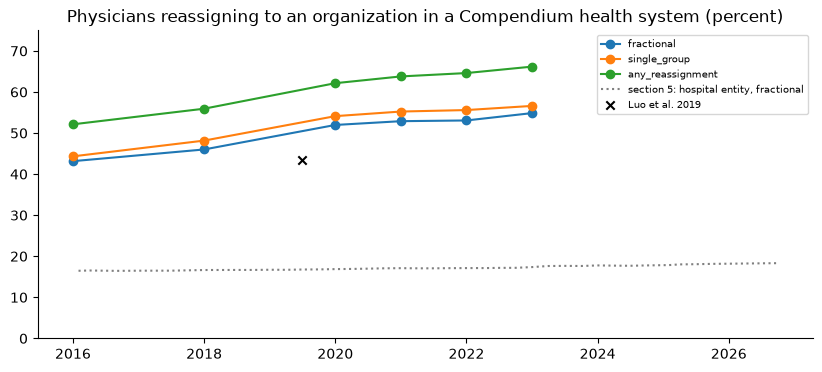

,physicians,fractional,single_group,any_reassignment,fractional_hospital_file_only
year,,,,,
2016,654731,43.2,44.3,52.1,9.9
2018,686496,46.0,48.2,55.9,10.5
2020,733180,52.0,54.1,62.1,11.1
2021,759956,52.9,55.2,63.8,11.2
2022,780551,53.1,55.6,64.6,11.3
2023,795805,54.9,56.6,66.2,11.4


In [19]:
con.execute("""
CREATE TABLE system_org AS
-- an organization is in a system through its own tax id (group practice file; for 2023, the 2022 file carried
-- forward) or through a hospital enrollment whose CCN AHRQ places in a system (hospital file, by hospital_link)
SELECT c.year, l.node_id AS pac_id, l.health_sys_id, l.via AS route FROM compendium_q c
JOIN system_link l ON l.year = c.year AND l.node_type = 'organization' AND l.health_sys_id IS NOT NULL
UNION
SELECT c.year, h.organization_pac_id, l.health_sys_id, 'hospital file' FROM compendium_q c
JOIN hospital_link h ON h.effective_date <= c.as_of_date AND (h.end_date IS NULL OR h.end_date > c.as_of_date)
JOIN system_link l ON l.year = c.year AND l.node_type = 'hospital' AND l.node_id = h.ccn AND l.health_sys_id IS NOT NULL
""")
system_share = con.sql("""
WITH e AS (
    SELECT c.year, e.practitioner_pac_id, e.k,
           e.organization_pac_id IN (SELECT pac_id FROM system_org s WHERE s.year = c.year) AS sys,
           e.organization_pac_id IN (SELECT pac_id FROM system_org s WHERE s.year = c.year AND route = 'hospital file') AS sys_hospital
    FROM compendium_q c JOIN physician_edge e ON e.as_of_date = c.as_of_date)
SELECT year, count(DISTINCT practitioner_pac_id) AS physicians,
       100 * sum(sys::INT / k) / count(DISTINCT practitioner_pac_id) AS fractional,
       100 * avg(sys::INT) FILTER (WHERE k = 1) AS single_group,
       100 * count(DISTINCT practitioner_pac_id) FILTER (WHERE sys) / count(DISTINCT practitioner_pac_id) AS any_reassignment,
       100 * sum(sys_hospital::INT / k) / count(DISTINCT practitioner_pac_id) AS fractional_hospital_file_only
FROM e GROUP BY 1 ORDER BY 1""").df().set_index("year")
# the full measure needs that year's group practice file (none for 2023); the hospital route alone covers every year
no_group_file = ~system_share.index.isin(con.sql("SELECT DISTINCT year FROM system_link WHERE node_type = 'organization'").df().year)
system_share.loc[no_group_file, ["fractional", "single_group", "any_reassignment"]] = np.nan
ax = system_share[["fractional", "single_group", "any_reassignment"]].plot(marker="o",
     title="Physicians reassigning to an organization in a Compendium health system (percent)")
ax.plot(vi.index.year + (vi.index.dayofyear - 1) / 365, vi["fractional"], color="grey", ls=":", label="section 5: hospital entity, fractional")
ax.scatter([2019.5], [43.5], marker="x", color="k", zorder=5, label="Luo et al. 2019")
ax.legend(fontsize=7); ax.set_xlabel(""); ax.set_ylim(0, 75); plt.show()
system_share.round(1)

In [20]:
con.sql("""
SELECT c.year, s.specialty, 100 * sum((o.pac_id IS NOT NULL)::INT / e.k) / sum(1.0 / e.k) AS pct_in_system_fractional
FROM compendium_q c
JOIN physician_edge e ON e.as_of_date = c.as_of_date
JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
LEFT JOIN (SELECT DISTINCT year, pac_id FROM system_org) o ON o.year = c.year AND o.pac_id = e.organization_pac_id
WHERE s.specialty IS NOT NULL AND c.year IN (2016, 2022)
GROUP BY ALL
""").df().pivot(index="specialty", columns="year", values="pct_in_system_fractional").sort_values(2022, ascending=False).round(1)

year,2016,2022
specialty,,
oncology,53.6,65.6
cardiology,52.1,64.5
primary care,45.1,53.9
obstetrics/gynecology,41.1,51.9
gastroenterology,38.8,51.4
orthopedic surgery,31.5,44.2
dermatology,25.0,28.2


**About half of physicians bill through a system organization, and the share rises by twelve points in seven years**: 43.2 percent in 2016 to 53.1 percent in 2022 and 54.9 percent in 2023, fractional (52.1 to 66.2 with any reassignment). Part of the 2018-2020 step is the linkage, not the market: the share of AHRQ's tax ids found in the graph rises from 87 to 98 percent between those editions, and the MD-PPAS benchmark itself rises 2.9 points to the graph's 6.0. AHRQ published no group practice file for 2023, so `graph-build` carries the 2022 file's organizations forward (`via` = 'carried forward from 2022'), keeping a system only if it is in the 2023 list (23 systems with 0.6 percent of system physicians are not). Carrying forward is what the files support: across consecutive editions an associate id keeps its system label 96 percent of the time (96 percent weighted by physicians; 88 percent precision and recall for being in a system), and 1.4 percent of physicians are in tax ids new to the file. Matching AHRQ's 2023 outpatient-site file to organizations by address and name does worse: scored against the 2022 group practice file, an address match is right about the system 54 percent of the time, and adding a name match raises that to 84 percent while finding only 27 percent of system practices, because systems own medical office buildings full of independent practices. 2023 is therefore last year's practices on this year's systems and misses practices acquired during 2023. The hospital route alone, practices billing under a hospital's own enrollment, carries 10 to 11 percent and is nearly flat, which is section 5's point again.

Against Luo et al.'s 43.5 percent for 2019, the system measure sits a few points higher (46.0 in 2018, 52.0 in 2020). The definitions differ in known directions: Luo et al. count a physician only when 75 percent or more of their Medicare billing goes through hospital-related tax ids, which is stricter than a fractional share, and AHRQ's systems need a group of physicians as well as a hospital. Where section 5's basic measure stayed near 17 percent, AHRQ's ownership network finds three times as many physicians, the size of the gap Luo et al. report between their basic and full measures.

By specialty, oncology and cardiology are the most integrated and gain 12 points between 2016 and 2022, the pattern Nikpay, Richards and Penson found with vendor data for 2007 to 2017; section 5's hospital-entity measure moved by one to four points for the same specialties over a longer window. Dermatology stays the least integrated.

Facilities, from the same files:


In [21]:
con.sql("""
WITH l AS (
    SELECT l.*, c.as_of_date FROM system_link l JOIN compendium_q c USING (year) WHERE l.node_type <> 'organization'),
n AS (SELECT c.year, f.ccn, 'hospital' AS node_type FROM compendium_q c JOIN hospital f
        ON f.effective_date <= c.as_of_date AND (f.end_date IS NULL OR f.end_date > c.as_of_date)
      UNION ALL
      SELECT c.year, f.ccn, f.facility_type FROM compendium_q c JOIN post_acute_facility f
        ON f.effective_date <= c.as_of_date AND (f.end_date IS NULL OR f.end_date > c.as_of_date)),
k AS (SELECT DISTINCT c.year, k.ccn FROM compendium_q c JOIN hospital_link k
        ON k.effective_date <= c.as_of_date AND (k.end_date IS NULL OR k.end_date > c.as_of_date)
      UNION
      SELECT DISTINCT c.year, k.ccn FROM compendium_q c JOIN post_acute_link k
        ON k.effective_date <= c.as_of_date AND (k.end_date IS NULL OR k.end_date > c.as_of_date))
SELECT l.year, l.node_type, count(*) AS listed, 100 * count(l.health_sys_id) / count(*) AS pct_in_system,
       count(n.ccn) AS graph_node, count(k.ccn) AS with_enrollment_link,
       count(k.ccn) FILTER (WHERE l.health_sys_id IS NOT NULL) AS in_system_with_enrollment_link
FROM l LEFT JOIN n ON n.year = l.year AND n.ccn = l.node_id AND n.node_type = l.node_type
LEFT JOIN k ON k.year = l.year AND k.ccn = l.node_id AND n.ccn IS NOT NULL
GROUP BY 1, 2 ORDER BY 2, 1
""").df().round(1)

,year,node_type,listed,pct_in_system,graph_node,with_enrollment_link,in_system_with_enrollment_link
0,2020,home_health,9638,9.9,7507,5819,623
1,2021,home_health,12544,8.2,7566,5885,624
2,2022,home_health,12972,9.3,7779,5888,628
3,2023,home_health,12809,7.7,7692,5615,574
4,2016,hospital,6214,58.9,6017,5037,2969
5,2018,hospital,6591,58.5,6108,5159,3096
6,2020,hospital,6574,61.3,6030,5140,3233
7,2021,hospital,6599,61.6,6024,5170,3256
8,2022,hospital,6632,62.7,6042,5216,3323
9,2023,hospital,6676,62.7,6033,5203,3313


Between 59 and 63 percent of AHRQ's listed hospitals are in a system each year, and 6 to 10 percent of nursing homes and home health agencies. The graph holds nearly all of AHRQ's hospitals and nursing homes as nodes: 6,017 to 6,108 of 6,214 to 6,676 hospital CCNs and 14,482 to 14,727 of 14,730 to 15,001 nursing homes. It holds 7,507 to 7,779 of AHRQ's 9,638 to 12,972 home health CCNs; the rest are not active Medicare-certified agencies in POS on that date. Through the enrollment links, 2,969 to 3,323 system hospitals, 733 to 985 system nursing homes and 574 to 628 system home health agencies connect to the organization that bills for them.


## 7. Market concentration with health systems as firms

Section 4 measured concentration with tax ids as firms; the papers roll practices up to the systems that own them. Section 6's system links make that possible. The published physician HHIs split by how they assign market shares:

* **Claims-based**: Capps, Dranove and Ody (*Health Affairs* 2017: 22 percent of physician markets highly concentrated in 2013), Baker, Bundorf and Royalty (Medicare carrier claims, 1998-2010), Koch, Wendling and Wilson (*HSR* 2018) and the FTC's *Atlas of US Physician Practice Choice and Firm Structure* (2026) measure shares in dollars or services and markets by where patients live. The graph has neither, so none of these can be reproduced.
* **Physician counts**: Fulton (*Health Affairs* 2017) measured concentration in each metropolitan statistical area with physician-count shares of SK&A's physician organizations, under the 2010 Merger Guidelines. In 2016, 39 percent of the 382 MSAs were highly concentrated (HHI above 2,500) for primary care physicians and 65 percent for specialists, and primary care concentration rose most over 2010-16 as hospitals and systems acquired practices. That is the graph's kind of measure.

The construction: a physician's practice ZIP (NPPES) places them in a metropolitan CBSA of the Census Bureau's July 2015 delineation (`reference/zcta_county.csv` and `reference/county_cbsa_2015.csv`: each ZIP's ZCTA goes to the county holding most of its 2010 population; Puerto Rico excluded), which has Fulton's 382 MSAs. Shares are physicians, `1/k` for a physician with `k` reassignments. A firm is the organization's system when it has one (section 6's `system_org`, its own tax id's system before a hospital's), else its tax id; both are shown. Fulton's specialty grouping is not public, so two versions: each product pooled into one market, or each Medicare specialty its own market, averaged within the MSA by physicians.


In [22]:
con.execute("""
CREATE TABLE firm_share AS
-- each physician's 1/k share of each organization on each Compendium year's quarter; the firm is the tax id
-- (associate id) or, when the organization is in a system, the system (its own tax id's system first)
WITH sys AS (
    SELECT year, pac_id, arg_min(health_sys_id, CASE WHEN route = 'hospital file' THEN 2 ELSE 1 END) AS health_sys_id
    FROM system_org GROUP BY 1, 2)
SELECT c.year, e.practitioner_pac_id, 1.0 / e.k AS wt, p.practice_zip5, s.primary_care,
       -- the physician's Medicare specialty: the lowest primary care code for a primary care physician, else the
       -- lowest specialty code that is not primary care
       coalesce(CASE WHEN s.primary_care
                     THEN list_min(list_filter(p.provider_type_codes, x -> x IN ('14-01', '14-08', '14-11', '14-37', '14-38')))
                     ELSE list_min(list_filter(p.provider_type_codes,
                          x -> x LIKE '14-%' AND x NOT IN ('14-01', '14-08', '14-11', '14-37', '14-38'))) END, 'other') AS specialty_code,
       e.organization_pac_id AS firm_tax_id, coalesce(sys.health_sys_id, e.organization_pac_id) AS firm_system
FROM compendium_q c
JOIN physician_edge e ON e.as_of_date = c.as_of_date
JOIN physician_q p ON p.as_of_date = e.as_of_date AND p.pac_id = e.practitioner_pac_id
JOIN physician_specialty s ON s.as_of_date = e.as_of_date AND s.pac_id = e.practitioner_pac_id
LEFT JOIN sys ON sys.year = c.year AND sys.pac_id = e.organization_pac_id
""")
con.execute("""
CREATE TABLE msa_hhi AS
-- metropolitan CBSAs (2015 delineation, Puerto Rico excluded); primary care and specialists are each either one
-- pooled product or each Medicare specialty its own, averaged over the specialties by physicians
WITH f AS (
    SELECT f.*, z.cbsa, CASE WHEN f.primary_care THEN 'primary care' ELSE 'specialists' END AS product,
           firm.firm_def, firm.firm
    FROM firm_share f
    JOIN cbsa z ON z.zip5 = f.practice_zip5 AND z.cbsa_type = 'metro' AND left(z.county_fips, 2) <> '72'
    CROSS JOIN LATERAL (VALUES ('tax id', f.firm_tax_id), ('system', f.firm_system)) firm(firm_def, firm)),
pooled AS (
    SELECT year, cbsa, product, firm_def, sum(physicians) AS physicians,
           sum(power(100 * physicians, 2)) / power(sum(physicians), 2) AS hhi
    FROM (SELECT year, cbsa, product, firm_def, firm, sum(wt) AS physicians FROM f GROUP BY ALL)
    GROUP BY ALL),
by_specialty AS (
    SELECT year, cbsa, product, firm_def, specialty_code, sum(physicians) AS physicians,
           sum(power(100 * physicians, 2)) / power(sum(physicians), 2) AS hhi
    FROM (SELECT year, cbsa, product, firm_def, specialty_code, firm, sum(wt) AS physicians FROM f
          WHERE specialty_code <> 'other' GROUP BY ALL)
    GROUP BY ALL)
SELECT year, cbsa, product, firm_def, 'pooled' AS markets, physicians, hhi FROM pooled
UNION ALL
SELECT year, cbsa, product, firm_def, 'by specialty', sum(physicians), sum(hhi * physicians) / sum(physicians)
FROM by_specialty GROUP BY ALL
""")
fulton = con.sql("""
SELECT year, product, markets, firm_def, count(*) AS msas,
       100 * avg((hhi > 2500)::INT) AS pct_highly_concentrated, median(hhi) AS median_hhi
FROM msa_hhi
GROUP BY ALL ORDER BY product, markets DESC, firm_def DESC, year
""").df()
fulton.pivot(index=["product", "markets", "firm_def"], columns="year", values="pct_highly_concentrated").round(1)

year                                2016  2018  2020  2021  2022  2023
product      markets      firm_def                                    
primary care by specialty system    20.9  20.4  20.7  18.6  17.5  18.1
                          tax id    13.6  12.8  11.0  10.7   8.9   9.2
             pooled       system    13.1  12.3  12.3  13.1  12.0  11.8
                          tax id     8.1   7.3   6.8   6.3   6.3   5.8
specialists  by specialty system    67.5  66.5  64.9  63.6  61.8  63.1
                          tax id    62.8  62.0  58.4  55.5  50.5  50.8
             pooled       system     7.9   7.9   9.4  10.2   8.6   8.1
                          tax id     3.4   3.7   3.7   3.7   3.1   3.1

**Specialists reproduce; primary care does not.** With systems as firms and each specialty its own market, 67.5 percent of MSAs are highly concentrated for specialists in 2016, against Fulton's 65 percent (62.8 percent with tax ids as firms). Pooling all specialists into one market gives 8 percent, so Fulton's specialist markets must be specialty by specialty. For primary care the graph finds 21 percent by specialty and 13 percent pooled, against Fulton's 39 percent. Splitting primary care by specialty and rolling practices up to systems both raise the share, and the gap that remains is not explained by anything public about Fulton's method; the candidates are SK&A's universe (office-based physicians, including those without Medicare enrollment) and SK&A's ownership roll-up, which may reach further than AHRQ's systems.

**After 2016 concentration does not rise.** With systems as firms, specialists fall from 67.5 to 63.1 percent of MSAs highly concentrated by 2023 and primary care from 20.9 to 18.1. Fulton found primary care concentration rising fastest in 2010-16; in this graph that did not continue. With tax ids as firms the decline is steeper (62.8 to 50.8 for specialists), partly the fractional-weight artifact section 4 identified: a physician who adds reassignments spreads over more tax ids. Rolling tax ids into systems absorbs much of that spreading.

The same roll-up on section 4's markets, HRR by specialty group:


In [23]:
con.execute("""
CREATE TABLE hrr_hhi AS
-- section 4's markets (HRR x specialty group), with tax ids or systems as firms, fractional shares
WITH f AS (
    SELECT f.year, h.hrr, s.specialty, firm.firm_def, firm.firm, sum(f.wt) AS physicians
    FROM firm_share f
    JOIN compendium_q c ON c.year = f.year
    JOIN physician_specialty s ON s.as_of_date = c.as_of_date AND s.pac_id = f.practitioner_pac_id
    JOIN hrr h ON h.zip5 = f.practice_zip5
    CROSS JOIN LATERAL (VALUES ('tax id', f.firm_tax_id), ('system', f.firm_system)) firm(firm_def, firm)
    WHERE s.specialty IS NOT NULL
    GROUP BY ALL)
SELECT year, hrr, specialty, firm_def, sum(physicians) AS physicians,
       sum(power(100 * physicians, 2)) / power(sum(physicians), 2) AS hhi
FROM f GROUP BY ALL
""")
con.sql("""
SELECT specialty, firm_def, year, 100 * avg((hhi > 2500)::INT) AS pct_highly_concentrated
FROM hrr_hhi GROUP BY ALL
""").df().pivot(index=["specialty", "firm_def"], columns="year", values="pct_highly_concentrated").round(1)

year                            2016  2018  2020  2021  2022  2023
specialty             firm_def                                    
cardiology            system    29.4  31.0  30.7  31.0  28.4  28.8
                      tax id    19.6  19.9  16.7  16.3  13.7  12.7
dermatology           system    32.8  31.4  29.7  28.1  26.1  25.8
                      tax id    30.8  29.7  26.5  25.2  23.5  22.9
gastroenterology      system    43.5  41.5  43.1  41.2  38.9  38.6
                      tax id    39.5  37.6  36.6  35.0  32.0  32.0
obstetrics/gynecology system    14.7  16.0  14.4  15.7  15.0  14.4
                      tax id    10.8   9.8   7.8   8.2   7.8   6.9
oncology              system    41.5  42.5  41.8  40.8  38.2  39.9
                      tax id    33.0  34.3  30.4  27.5  25.8  24.2
orthopedic surgery    system    23.9  22.2  25.2  21.6  21.6  22.9
                      tax id    21.6  19.0  19.6  17.6  17.0  16.3
primary care          system     5.9   4.6   4.6   4.9   5.9   5.9
                      tax id     2.3   2.0   1.3   1.6   1.3   1.3

Rolling practices up to systems raises the share of highly concentrated HRR markets in every specialty, and by more each year: cardiology from 19.6 to 29.4 percent in 2016 and from 12.7 to 28.8 in 2023, oncology from 33.0 to 41.5 and from 24.2 to 39.9. With tax ids as firms concentration seems to fall, but under system firms it is flat in cardiology, oncology, orthopedics, obstetrics and primary care and falls in gastroenterology and dermatology. This matches section 4b's Medicaid main-group result (flat, 2018-2025): the decline is in how physicians spread across tax ids, while the systems that own those tax ids hold their markets. Across the seven specialty groups, 27 percent of HRR markets are highly concentrated in 2016 under system firms, near Capps, Dranove and Ody's 22 percent for 2013, but their markets are claims-based patient-flow areas and nine specialties, so this is a comparison of magnitude, not a replication.

The system roll-up itself can be checked against two published Compendium-based measures. Machta et al. (*HSR* 2020) report the median MSA's share of physicians in systems: 30 percent in 2016 and 40 percent in 2018, and in 2018 57 percent for hematology-oncology, 55 for cardiology, 44 for general surgery, 42 for neurology, 7 for ophthalmology and 6 for dermatology. Furukawa et al. (*Health Affairs* 2020) report 40 and 51 percent of all physicians in systems in 2016 and 2018.


In [24]:
con.sql("""
-- Machta et al. (2020): the median MSA's share of physicians in systems, by specialty; Furukawa et al. (2020):
-- the national share
WITH f AS (
    SELECT f.year, z.cbsa, f.wt, f.firm_system <> f.firm_tax_id AS in_system,
           CASE WHEN f.primary_care THEN 'primary care'
                WHEN f.specialty_code = '14-06' THEN 'cardiology'
                WHEN f.specialty_code IN ('14-82', '14-83', '14-90') THEN 'hematology-oncology'
                WHEN f.specialty_code = '14-02' THEN 'general surgery'
                WHEN f.specialty_code = '14-13' THEN 'neurology'
                WHEN f.specialty_code = '14-18' THEN 'ophthalmology'
                WHEN f.specialty_code = '14-07' THEN 'dermatology' END AS specialty
    FROM firm_share f
    JOIN cbsa z ON z.zip5 = f.practice_zip5 AND z.cbsa_type = 'metro' AND left(z.county_fips, 2) <> '72'),
m AS (SELECT year, cbsa, CASE WHEN grouping(specialty) = 1 THEN 'all physicians' ELSE specialty END AS specialty,
             sum(wt * in_system::INT) / sum(wt) AS share
      FROM f GROUP BY GROUPING SETS ((year, cbsa, specialty), (year, cbsa)))
SELECT specialty, year, 100 * median(share) AS median_msa_pct_in_system
FROM m WHERE specialty IS NOT NULL AND year IN (2016, 2018, 2022, 2023)
GROUP BY ALL
""").df().pivot(index="specialty", columns="year", values="median_msa_pct_in_system").round(1)

year,2016,2018,2022,2023
specialty,,,,
all physicians,37.2,41.3,49.1,51.3
cardiology,50.9,57.4,67.7,70.5
dermatology,5.9,6.2,11.1,11.4
general surgery,40.0,50.0,64.4,68.6
hematology-oncology,47.5,54.2,66.7,70.0
neurology,45.8,50.0,66.2,70.0
ophthalmology,3.3,3.9,6.3,6.7
primary care,39.7,45.7,51.3,53.4


**The roll-up matches Machta et al. by specialty.** In 2018 the graph's median MSA has 57.4 percent of cardiologists in systems (Machta: 55), 54.2 percent of hematologist-oncologists (57), 6.2 percent of dermatologists (6) and 3.9 percent of ophthalmologists (7); general surgery and neurology run 6 to 8 points higher (50 against 44 and 42). The median over all physicians is 37.2 percent in 2016 and 41.3 percent in 2018, against 30 and 40. Nationally the graph has 43.2 and 46.0 percent of physicians in systems in 2016 and 2018 (section 6), against Furukawa et al.'s 40 and 51: the same 2016 level, half the growth to 2018. Machta and Furukawa counted physicians with IQVIA's OneKey; the graph counts Medicare billing, and its 2018 linkage covers 87 percent of AHRQ's tax ids. By 2023 the median MSA has 70 percent of its cardiologists, hematologist-oncologists and neurologists in systems.

## 8. What the graph cannot say, and next steps

* **A reassignment is a billing permission, not employment or ownership.** The AHRQ Compendium of U.S. Health Systems declined to use PECOS for that reason, and because one system can spread its physicians over many tax ids.
* **The PPEF has no volume.** Every rule the papers use to choose a physician's main firm (plurality of charges, 50 percent of allowed amounts) needs claims, and section 4 shows the choice changes the answer. Section 4b borrows Medicaid volume, which covers four in ten multi-group physicians, from 2018 to 2024.
* **An associate id is a tax id, not a system.** Section 6 borrows AHRQ's systems through 2023 (practices carried forward from 2022); later years need an ownership layer of the graph's own.
* **Physician counts are not claims.** Section 7 reproduces the physician-count HHIs (Fulton's specialists) but not the claims-based ones, whose shares are dollars and whose markets are where patients live.

Next steps, each a published measure the graph is now ready for, not done here:

1. **Ownership edges.** CMS publishes monthly *All Owners* files for hospitals, nursing homes, home health agencies and hospices since late 2022: each facility enrollment's direct and indirect owners, by associate id, with percentages, association dates and flags for private equity, REIT and holding-company owners. ASPE (Welch, Xu, De Lew and Sommers, 2023) inferred ultimate owners and chain sizes from the hospital file. Loading them adds owner -> organization edges keyed by the same associate ids as this graph.
2. **Systems after 2023.** Luo et al.'s component step over IRS Form 990 Schedule R, run on the graph's own ownership edges (step 1), with section 6 as the benchmark and section 7's HHIs extended to 2026.
3. **Other facility types.** Hospices and dialysis facilities as nodes, from the POS and iQIES files, linked by the same address rules as nursing homes and home health agencies.
4. **A claims-based main group.** The public *Doctors and Clinicians* file (formerly Physician Compare) lists each clinician's group associate ids after CMS's 12-month billing filter, and hospital affiliations by CCN. Its archived editions (quarterly from 2014, captured by the Internet Archive through 2022) would show how much of section 3's remaining 3 to 5 point gap is stale reassignments, and give a second, Medicare-side main-group rule to set beside section 4b's.